<a href="https://colab.research.google.com/github/Joshua-A-tech/ALX_python/blob/main/Normality_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Generated synthetic dataset 'cybersecurity_employee_dataset.csv'


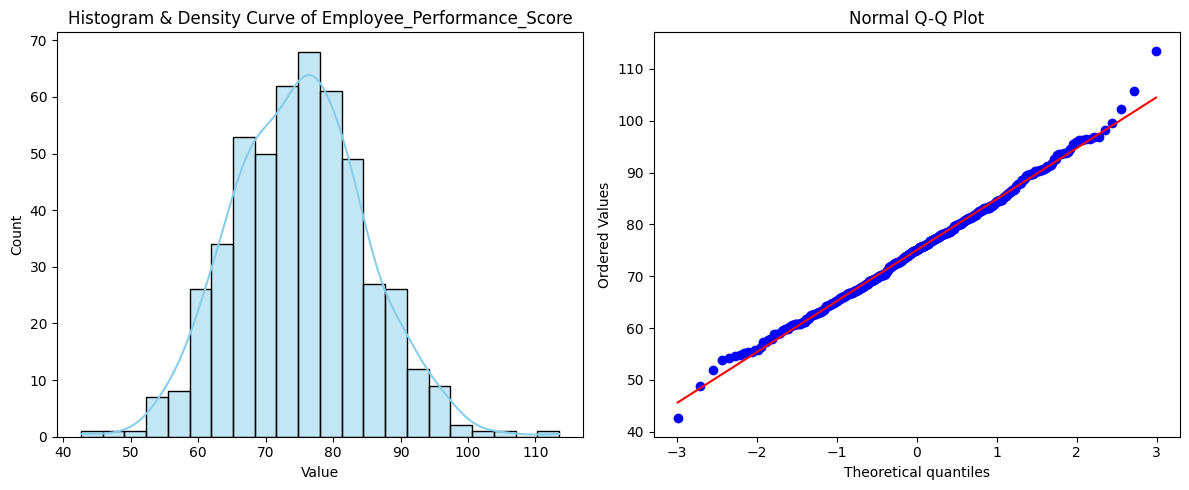

Shapiro-Wilk Test: Statistic = 0.9967, p-value = 0.4013
D'Agostino's K^2 Test: Statistic = 4.2235, p-value = 0.1210
Result: Data looks Gaussian / normal (fail to reject the null hypothesis).


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

# Create a synthetic dataset since the original file is missing
np.random.seed(42)
n_samples = 500
synthetic_data = {
    'Employee_ID': [f'EMP{i:03d}' for i in range(1, n_samples + 1)],
    'Employee_Performance_Score': np.random.normal(loc=75, scale=10, size=n_samples), # Normally distributed
    'Security_Incidents_Reported': np.random.poisson(lam=1.5, size=n_samples) # Not normally distributed
}

df_synthetic = pd.DataFrame(synthetic_data)
df_synthetic.to_csv('cybersecurity_employee_dataset.csv', index=False)
print("Generated synthetic dataset 'cybersecurity_employee_dataset.csv'")

# 1. Load the data using pandas
df = pd.read_csv('cybersecurity_employee_dataset.csv')

# Select the target column ('Employee_Performance_Score' for testing normality)
target_column = 'Employee_Performance_Score'
data = df[target_column].dropna()

# 2. Visual Checks: Histogram (with KDE) and Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram with Kernel Density Estimate (KDE)
sns.histplot(data, kde=True, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title(f'Histogram & Density Curve of {target_column}')
axes[0].set_xlabel('Value')

# Q-Q (Quantile-Quantile) Plot
stats.probplot(data, dist='norm', plot=axes[1])
axes[1].set_title('Normal Q-Q Plot')

plt.tight_layout()
plt.show()

# 3. Statistical Tests for Normality
# Shapiro-Wilk Test
shapiro_stat, shapiro_p = stats.shapiro(data)
print(f'Shapiro-Wilk Test: Statistic = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}')

# D\'Agostino\'s K-squared Test
k2_stat, k2_p = stats.normaltest(data)
print(f"D'Agostino's K^2 Test: Statistic = {k2_stat:.4f}, p-value = {k2_p:.4f}")

# Automated Interpretation (alpha = 0.05)
alpha = 0.05
if shapiro_p > alpha:
    print('Result: Data looks Gaussian / normal (fail to reject the null hypothesis).')
else:
    print('Result: Data does NOT look Gaussian / normal (reject the null hypothesis).')

In [3]:
import os
print("Files in current directory:", os.listdir('.'))

Files in current directory: ['.config', 'sample_data']
